# Dummy Catastrophe Model, UK Flood Risk — Notebook 02: Flood Vulnerability and Insured Losses

**Objective:** Build an illustrative property-level flood loss calculation, moving from physical flood depth to damage and then to the insurer's payment.

**Learning Outcomes**
- Convert flood depth into a damage ratio using an explicitly defined vulnerability function.
- Calculate gross damage at property level.
- Apply policy deductibles and limits.
- Compare gross damage with insurer-paid loss.

**Important modelling caveat:** This notebook uses a simple, synthetic vulnerability curve for learning. It is not an industry-standard or calibrated flood vulnerability model, and the resulting losses are not forecasts, quotes, or estimates of actual insured losses. Real catastrophe models use hazard, vulnerability, exposure, financial terms and event modelling calibrated to appropriate data.

An illustrative vulnerability function has been defined using flood depth and damage ratio anchor points, with linear interpolation between them (see Section 2).

The insurance calculation follows:
>
> Insurer Loss = min(max(Gross Damage - Deductible,0),Policy Limit)

This ensures the insurer does not pay a negative amount (max chosen from damage minus deductible or zero) and does not pay more than the policy limit (min chosen from damage minus deductible and limit).

## 1. Load the portfolio

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "synthetic_uk_flood_portfolio_1000_geocoded.csv"
df = pd.read_csv(file_path)

print(f"Loaded {len(df):,} properties")
display(df.head())


Loaded 1,000 properties


,property_id,region,area,latitude,longitude,property_type,year_built,building_sum_insured_gbp,contents_sum_insured_gbp,total_sum_insured_gbp,deductible_gbp,policy_limit_gbp,illustrative_flood_zone,annual_flood_probability,baseline_flood_depth_m
0,P0001,East Anglia,Cambridge,52.153420,0.105548,Terraced,1932,147000,25000,172000,7500,185000,Medium,0.01539,0.182
1,P0002,East Anglia,Cambridge,52.235736,0.166611,Commercial,1929,460000,59000,519000,7500,460000,Low,0.00555,0.082
2,P0003,Yorkshire,York,53.922544,-1.083690,Flat,1981,170000,34000,204000,7500,175000,High,0.03961,0.442
3,P0004,Thames Valley,Reading,51.454193,-0.971377,Commercial,1913,553000,69000,622000,5000,610000,Low,0.00406,0.115
4,P0005,Severn Basin,Gloucester,51.877088,-2.270219,Semi-detached,1965,176000,50000,226000,5000,195000,High,0.04003,0.456


## 2. Define an illustrative vulnerability function

A **damage ratio** is the proportion of the property's insured value assumed to be damaged at a given flood depth. It ranges from 0 (no damage) to 1 (100% damage).

For this exercise, define the following synthetic depth-to-damage curve:

| Flood depth (m) | Damage ratio |
|---:|---:|
| 0.00 | 0% |
| 0.10 | 2% |
| 0.25 | 8% |
| 0.50 | 20% |
| 1.00 | 45% |
| 1.50 | 65% |
| 2.00 | 80% |
| 3.00 | 95% |

Between these anchor points, use **linear interpolation**. Below 0 m, damage is set to 0%; above 3 m, the damage ratio is capped at 95%.

This deliberately simple function assumes damage increases with depth. It does not distinguish property type, construction, contents, flood duration, contamination, velocity or other vulnerability drivers. Those omissions are limitations to discuss, not facts to hide.

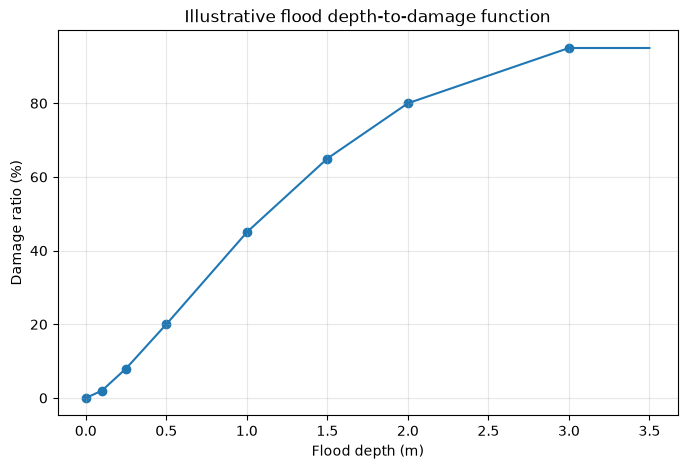

In [2]:
# Anchor points for the illustrative vulnerability function
depth_anchors_m = np.array([0.00, 0.10, 0.25, 0.50, 1.00, 1.50, 2.00, 3.00])
damage_anchors = np.array([0.00, 0.02, 0.08, 0.20, 0.45, 0.65, 0.80, 0.95])

def depth_to_damage_ratio(depth_m):
    """Convert flood depth (m) to an illustrative damage ratio (0 to 1)."""
    depth = np.asarray(depth_m, dtype=float)
    return np.interp(
        depth,
        depth_anchors_m,
        damage_anchors,
        left=0.0,
        right=damage_anchors[-1]
    )

# Plot the vulnerability function
depth_grid = np.linspace(0, 3.5, 200)
plt.figure(figsize=(8, 5))
plt.plot(depth_grid, depth_to_damage_ratio(depth_grid) * 100)
plt.scatter(depth_anchors_m, damage_anchors * 100)
plt.xlabel("Flood depth (m)")
plt.ylabel("Damage ratio (%)")
plt.title("Illustrative flood depth-to-damage function")
plt.grid(True, alpha=0.3)
plt.show()


The function is deterministic: the same depth always produces the same damage ratio. In reality, properties at the same depth can experience different damage.

## 3. Calculate property-level damage ratios

Apply the function to `baseline_flood_depth_m`. This exercise treats the supplied baseline depth as the depth associated with the loss scenario being modelled. It does **not** combine depth with annual flood probability; probability is a separate hazard-frequency input and is not needed to calculate conditional damage for this scenario.

In [3]:
df["damage_ratio"] = depth_to_damage_ratio(df["baseline_flood_depth_m"])

# Basic checks
assert df["damage_ratio"].between(0, 1).all()
assert df["damage_ratio"].notna().all()

display(
    df[["property_id", "baseline_flood_depth_m", "damage_ratio"]]
    .head(10)
)


,property_id,baseline_flood_depth_m,damage_ratio
0,P0001,0.182,0.05280
1,P0002,0.082,0.01640
2,P0003,0.442,0.17216
3,P0004,0.115,0.02600
4,P0005,0.456,0.17888
5,P0006,0.249,0.07960
6,P0007,0.073,0.01460
7,P0008,0.361,0.13328
8,P0009,0.069,0.01380
9,P0010,0.039,0.00780


## 4. Calculate gross damage at property level

For this exercise, assume the damage ratio applies to **total sum insured** (buildings plus contents):

**Gross damage = total sum insured × damage ratio**

Gross damage is the modelled physical damage before applying the policy deductible or policy limit. This is a simplifying assumption: a real model may apply different vulnerability functions and insured values to buildings and contents.

In [4]:
df["gross_damage_gbp"] = (
    df["total_sum_insured_gbp"] * df["damage_ratio"]
)

display(
    df[[
        "property_id",
        "total_sum_insured_gbp",
        "baseline_flood_depth_m",
        "damage_ratio",
        "gross_damage_gbp"
    ]].head(10).round(2)
)


,property_id,total_sum_insured_gbp,baseline_flood_depth_m,damage_ratio,gross_damage_gbp
0,P0001,172000,0.18,0.05,9081.60
1,P0002,519000,0.08,0.02,8511.60
2,P0003,204000,0.44,0.17,35120.64
3,P0004,622000,0.12,0.03,16172.00
4,P0005,226000,0.46,0.18,40426.88
5,P0006,164000,0.25,0.08,13054.40
6,P0007,165000,0.07,0.01,2409.00
7,P0008,129000,0.36,0.13,17193.12
8,P0009,189000,0.07,0.01,2608.20
9,P0010,575000,0.04,0.01,4485.00


## 5. Apply deductibles and policy limits

Use the following simplified policy-payment calculation:

1. Subtract the deductible from gross damage, with a floor of zero.
2. Cap the resulting amount at the policy limit.

**Insurer-paid loss = min(max(gross damage − deductible, 0), policy limit)**

This assumes the deductible is applied before the policy limit, and that `policy_limit_gbp` is the maximum insurer payment for this loss. Actual policy wordings can include other structures, exclusions, sub-limits, coinsurance and aggregate limits.

In [5]:
df["loss_after_deductible_gbp"] = (
    df["gross_damage_gbp"] - df["deductible_gbp"]
).clip(lower=0)

df["insurer_paid_loss_gbp"] = np.minimum(
    df["loss_after_deductible_gbp"],
    df["policy_limit_gbp"]
)

# Financial logic checks
assert (df["loss_after_deductible_gbp"] >= 0).all()
assert (df["insurer_paid_loss_gbp"] >= 0).all()
assert (df["insurer_paid_loss_gbp"] <= df["policy_limit_gbp"]).all()
assert (df["insurer_paid_loss_gbp"] <= df["gross_damage_gbp"]).all()

display(
    df[[
        "property_id",
        "gross_damage_gbp",
        "deductible_gbp",
        "policy_limit_gbp",
        "loss_after_deductible_gbp",
        "insurer_paid_loss_gbp"
    ]].head(10).round(2)
)


,property_id,gross_damage_gbp,deductible_gbp,policy_limit_gbp,loss_after_deductible_gbp,insurer_paid_loss_gbp
0,P0001,9081.60,7500,185000,1581.60,1581.60
1,P0002,8511.60,7500,460000,1011.60,1011.60
2,P0003,35120.64,7500,175000,27620.64,27620.64
3,P0004,16172.00,5000,610000,11172.00,11172.00
4,P0005,40426.88,5000,195000,35426.88,35426.88
5,P0006,13054.40,5000,165000,8054.40,8054.40
6,P0007,2409.00,7500,175000,0.00,0.00
7,P0008,17193.12,10000,115000,7193.12,7193.12
8,P0009,2608.20,5000,165000,0.00,0.00
9,P0010,4485.00,2500,560000,1985.00,1985.00


## 6. Compare gross damage with insurer-paid loss

At portfolio level, compare:
- **Gross damage:** physical damage before policy terms.
- **Insurer-paid loss:** modelled payment after deductibles and policy limits.
- **Policyholder-retained amount:** the difference between gross damage and insurer-paid loss under this simplified calculation.

The retained amount includes the deductible and any loss above the policy limit.

In [6]:
df["policyholder_retained_gbp"] = (
    df["gross_damage_gbp"] - df["insurer_paid_loss_gbp"]
).clip(lower=0)

portfolio_comparison = pd.Series({
    "Total gross damage (£)": df["gross_damage_gbp"].sum(),
    "Total insurer-paid loss (£)": df["insurer_paid_loss_gbp"].sum(),
    "Total policyholder-retained amount (£)": df["policyholder_retained_gbp"].sum(),
    "Properties with positive gross damage": (df["gross_damage_gbp"] > 0).sum(),
    "Properties with positive insurer-paid loss": (df["insurer_paid_loss_gbp"] > 0).sum(),
})

display(portfolio_comparison.to_frame("value").style.format({
    "value": lambda x: f"{x:,.0f}" if isinstance(x, (int, float, np.integer, np.floating)) else str(x)
}))


,value
Total gross damage (£),"25,772,559"
Total insurer-paid loss (£),"21,102,189"
Total policyholder-retained amount (£),"4,670,369"
Properties with positive gross damage,"1,000"
Properties with positive insurer-paid loss,675


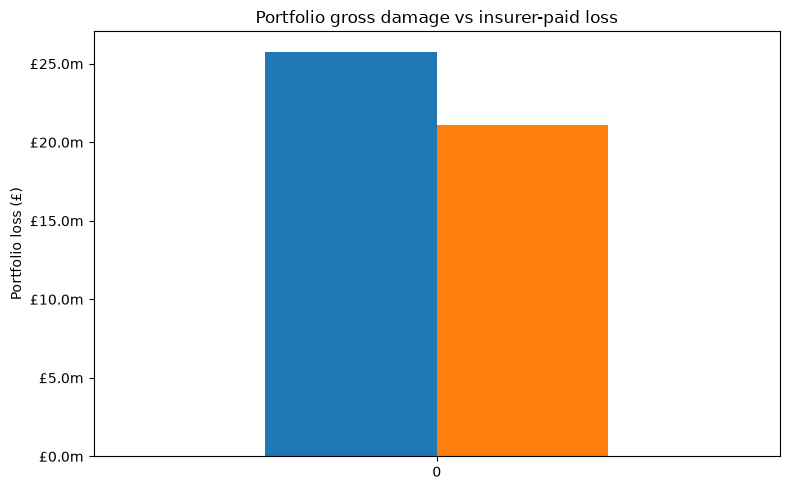

In [7]:
# Compare gross damage and insurer-paid loss
comparison = pd.DataFrame({
    "Gross damage": [df["gross_damage_gbp"].sum()],
    "Insurer-paid loss": [df["insurer_paid_loss_gbp"].sum()],
})

ax = comparison.plot(
    kind="bar",
    figsize=(8, 5),
    legend=False,
    rot=0
)
ax.set_ylabel("Portfolio loss (£)")
ax.set_title("Portfolio gross damage vs insurer-paid loss")
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"£{x / 1_000_000:.1f}m")
)
plt.tight_layout()
plt.show()


Some key observations at this stage:
- All properties in this model sustain some flood damage due to being above the baseline and the nature of the damage ratio
- Despite this, only approx two-thirds involve some sort of insurer payment.
- The insurer pays 81.9% of gross damage

## 7. Inspect the largest property-level losses

Sort by insurer-paid loss to identify which properties contribute most to the modelled insured loss. This is a useful bridge between portfolio-level totals and individual risk records.

In [8]:
largest_losses = df.sort_values(
    "insurer_paid_loss_gbp", ascending=False
)[[
    "property_id",
    "region",
    "area",
    "property_type",
    "total_sum_insured_gbp",
    "baseline_flood_depth_m",
    "damage_ratio",
    "gross_damage_gbp",
    "deductible_gbp",
    "policy_limit_gbp",
    "insurer_paid_loss_gbp"
]].head(10)

display(largest_losses.round(2))


,property_id,region,area,property_type,total_sum_insured_gbp,baseline_flood_depth_m,damage_ratio,gross_damage_gbp,deductible_gbp,policy_limit_gbp,insurer_paid_loss_gbp
957,P0958,Yorkshire,York,Detached,819000,1.16,0.51,420966.0,5000,925000,415966.0
820,P0821,Yorkshire,York,Commercial,786000,1.01,0.45,357472.8,5000,710000,352472.8
786,P0787,Severn Basin,Worcester,Detached,450000,1.66,0.70,313965.0,5000,385000,308965.0
994,P0995,Thames Valley,Reading,Semi-detached,640000,1.07,0.48,305152.0,2500,565000,302652.0
212,P0213,Thames Valley,Reading,Detached,839000,0.81,0.35,296167.0,5000,850000,291167.0
455,P0456,Severn Basin,Gloucester,Commercial,1084000,0.65,0.27,296474.0,10000,1235000,286474.0
749,P0750,East Anglia,Norwich,Commercial,848000,0.68,0.29,248040.0,5000,970000,243040.0
801,P0802,Severn Basin,Gloucester,Commercial,357000,1.43,0.62,221482.8,7500,360000,213982.8
870,P0871,Yorkshire,York,Semi-detached,298000,1.69,0.71,210775.4,10000,270000,200775.4
770,P0771,Yorkshire,York,Commercial,709000,0.68,0.29,204192.0,5000,675000,199192.0


## 8. Regional comparison

Aggregate gross damage and insurer-paid loss by region. This shows how policy terms change the financial outcome relative to gross physical damage.

Do not interpret these outputs as annual expected losses: this notebook models one illustrative depth scenario and does not apply annual event probabilities or simulate a range of events.

In [9]:
regional_losses = (
    df.groupby("region")
    .agg(
        property_count=("property_id", "count"),
        total_tiv_gbp=("total_sum_insured_gbp", "sum"),
        gross_damage_gbp=("gross_damage_gbp", "sum"),
        insurer_paid_loss_gbp=("insurer_paid_loss_gbp", "sum"),
        retained_amount_gbp=("policyholder_retained_gbp", "sum")
    )
    .sort_values("insurer_paid_loss_gbp", ascending=False)
)

display(regional_losses.style.format({
    "total_tiv_gbp": "£{:,.0f}",
    "gross_damage_gbp": "£{:,.0f}",
    "insurer_paid_loss_gbp": "£{:,.0f}",
    "retained_amount_gbp": "£{:,.0f}",
}))


,property_count,total_tiv_gbp,gross_damage_gbp,insurer_paid_loss_gbp,retained_amount_gbp
region,,,,,
Severn Basin,243,"£85,630,000","£8,335,779","£7,125,772","£1,210,007"
Yorkshire,262,"£91,186,000","£6,782,055","£5,562,905","£1,219,151"
Thames Valley,235,"£78,654,000","£5,963,018","£4,917,989","£1,045,028"
East Anglia,260,"£90,373,000","£4,691,706","£3,495,523","£1,196,183"


In Notebook 01, Severn Basin was identified as having the highest mean annual flood probability, suggesting greater flood hazard within the portfolio.

Furthermore, despite representing a smaller share of total insured value than Yorkshire and East Anglia (24.8% of the portfolio), it accounts for the largest share of insurer-paid losses (33.8%). This reflects the combined impact of flood depths and insured values on gross damage, with deductibles and policy limits determining the final insurer-paid amount.

Together, these analyses suggest that risk is not evenly distributed across the portfolio, with Severn Basin representing a particularly important area for further investigation due to its higher flood hazard and disproportionate contribution to modelled losses.

## 9. Final validation checks

These checks test whether the calculations behave consistently with the assumptions in this notebook.

In [10]:
# No negative loss values
assert (df["gross_damage_gbp"] >= 0).all()
assert (df["insurer_paid_loss_gbp"] >= 0).all()
assert (df["policyholder_retained_gbp"] >= 0).all()

# Insurer payment cannot exceed gross damage or policy limit
assert (df["insurer_paid_loss_gbp"] <= df["gross_damage_gbp"] + 1e-8).all()
assert (df["insurer_paid_loss_gbp"] <= df["policy_limit_gbp"] + 1e-8).all()

# Gross damage is split between insurer payment and retained amount
assert np.allclose(
    df["gross_damage_gbp"],
    df["insurer_paid_loss_gbp"] + df["policyholder_retained_gbp"]
)

print("All validation checks passed.")


All validation checks passed.


**Limitations**
- The vulnerability curve is synthetic and not calibrated to claims or engineering evidence.
- One baseline depth per property is not an event set or a probabilistic hazard model.
- Damage ratio is applied to total sum insured, rather than modelling buildings and contents separately.
- The calculation does not model event footprints, correlated losses, flood duration, defence failure, business interruption or policy wording complexity.
- Annual flood probability is not used in this scenario loss calculation. A separate frequency-severity framework would be needed to estimate annualised loss.

## Key takeaway

This notebook demonstrates the chain from **hazard intensity (depth) → vulnerability (damage ratio) → gross damage → financial terms → insurer-paid loss**. In a catastrophe model, each stage has assumptions and uncertainty that need to be understood and communicated.